# Problem 6: Walking down a hill with Gradient Descent, Momentum, RMSProp and Adam

Group number: 8
Members: Manas Dogra (100006131), Monish Chopra (100007201), Aditya Aditya, Aaditya Dawer (100006382)
GitHub link: https://github.com/AadityaDawer/dsa-problem6-optimizers

## The story (read this first)
Imagine you are on top of a big hill and it is very foggy.
You cannot see the bottom. You can only feel the ground under your feet.
Your goal is to reach the lowest point of the valley.

A computer does the same thing when it "learns". The hill is a function f.
The lowest point is the best answer. We take small steps downhill until we get there.

In this notebook we try five ways of walking:
1. Gradient Descent: feel the slope, take a step.
2. Momentum: like a rolling ball, it keeps some speed from before.
3. RMSProp: takes small steps on steep ground and bigger steps on flat ground.
4. Adam: Momentum and RMSProp together.
5. Newton: looks at the real shape of the hill (fast, but expensive).

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

## Part 1: The walkers (optimizers)
Every walker has a function called `step`.
We give it where we stand now (`w`) and the slope (`g`, the gradient).
It gives back the next place to stand.
`lr` is the learning rate, it means "how big is one step".

### Walker 1: Gradient Descent
The slope points uphill, so we walk the other way: new place = old place - lr * slope.
That is all. This walker has no memory.

In [2]:
class GD:
    def __init__(self, lr):
        self.lr = lr

    def step(self, w, g):
        return w - self.lr * g

### Walker 2: Momentum
This walker remembers the past. It keeps a number `v` (the speed).
Each time, the new speed is a mix: a bit of the old speed and a bit of the new slope.
A rolling ball does not change direction suddenly, and neither does this walker.
So it zig-zags less.

In [3]:
class Momentum:
    def __init__(self, lr, beta=0.9):
        self.lr = lr
        self.beta = beta
        self.v = 0          # speed, starts at zero

    def step(self, w, g):
        self.v = self.beta * self.v + (1 - self.beta) * g
        return w - self.lr * self.v

### Walker 3: RMSProp
This walker remembers how steep the ground was. It keeps `s`, the average of g squared.
If the ground is very steep, `s` is big, and we divide by it, so the step becomes small.
If the ground is flat, `s` is small, so the step becomes bigger.
So every direction gets a step size that fits it.
(`eps` is a tiny number so we never divide by zero.)

In [4]:
class RMSProp:
    def __init__(self, lr, beta=0.9, eps=1e-8):
        self.lr = lr
        self.beta = beta
        self.eps = eps
        self.s = 0          # how steep it was, starts at zero

    def step(self, w, g):
        self.s = self.beta * self.s + (1 - self.beta) * g**2
        return w - self.lr * g / (np.sqrt(self.s) + self.eps)

### Walker 4: Adam
Adam uses both tricks: speed `m` (like Momentum) and steepness `s` (like RMSProp).
There is one more trick. At the start, `m` and `s` begin at zero, so they are too small.
Like a cup that starts empty and is not full yet. So we fix it by dividing by (1 - beta^t).
`t` just counts the steps. After many steps this fix does almost nothing.

In [5]:
class Adam:
    def __init__(self, lr, beta1=0.9, beta2=0.999, eps=1e-8):
        self.lr, self.eps = lr, eps
        self.beta1, self.beta2 = beta1, beta2
        self.m, self.s, self.t = 0, 0, 0

    def step(self, w, g):
        self.t += 1
        self.m = self.beta1 * self.m + (1 - self.beta1) * g
        self.s = self.beta2 * self.s + (1 - self.beta2) * g**2
        m_fixed = self.m / (1 - self.beta1**self.t)
        s_fixed = self.s / (1 - self.beta2**self.t)
        return w - self.lr * m_fixed / (np.sqrt(s_fixed) + self.eps)

### Walker 5: Newton
Newton does not only feel the slope, it also knows how curved the hill is.
The curvature is stored in a table of numbers called the Hessian (we call it H).
With H, Newton can jump much closer to the bottom.
The problem: H has d x d numbers, which is huge when d is big.

In [6]:
class Newton:
    def step(self, w, g, H):
        return w - np.linalg.solve(H, g)

## Part 2: Do the walkers give the same answers as our hand calculations?
We use the small hill from the exam sheet: f(w1, w2) = 0.5*w1^2 + 5*w2^2.
Its slope is (w1, 10*w2). We start at (4, 1), so the first slope is (4, 10).
`assert` means "this must be true". If it is not true, Python shows an error.

In [7]:
def slope(w):
    return np.array([w[0], 10 * w[1]])

start = np.array([4.0, 1.0])

def same(a, b):
    return np.allclose(a, b, atol=1e-4)

# Question 1: gradient descent with lr = 0.18
walker = GD(0.18)
w1 = walker.step(start, slope(start))
w2 = walker.step(w1, slope(w1))
assert same(w1, [3.28, -0.8])
assert same(w2, [2.6896, 0.64])

# Question 2: momentum with beta = 0.5 and lr = 0.18
walker = Momentum(0.18, 0.5)
w1 = walker.step(start, slope(start))
w2 = walker.step(w1, slope(w1))
assert same(w1, [3.64, 0.1])
assert same(w2, [3.1324, -0.44])
print("Question 1 and 2 are correct")

Question 1 and 2 are correct


In [8]:
# Question 3: RMSProp and Adam, one step, beta = 0.9, eps = 0, lr = 0.5
g = slope(start)
rms = RMSProp(0.5, 0.9, 0)
assert same(rms.step(start, g), [2.4189, -0.5811])
adam = Adam(0.5, 0.9, 0.9, 0)
assert same(adam.step(start, g), [3.5, 0.5])

# Question 5: Newton on this hill needs only ONE step
H = np.diag([1.0, 10.0])
assert same(Newton().step(start, g, H), [0, 0])

# Extra check: with beta = 0, Momentum is the same as plain GD
g2 = np.array([0.3, 0.7])
w = np.array([1.0, -2.0])
assert same(Momentum(0.1, 0).step(w, g2), GD(0.1).step(w, g2))
print("Question 3 and 5 are correct")

Question 3 and 5 are correct


Both messages printed, so our code gives the same numbers as the hand work.

## Part 3: Experiment 1, watching the walkers on two hills
We put every walker at the same start point (-1.5, 2.0) and let it walk 200 steps.

Hill 1, the Canyon: f = 0.5*w1^2 + 25*w2^2.
It is very steep one way and almost flat the other way, like a long narrow valley.

Hill 2, Rosenbrock: f = (1-w1)^2 + 100*(w2-w1^2)^2.
It is a banana-shaped valley. It is famous for being hard.

For each hill we write: the height f, the slope, and the curvature H.

In [9]:
def canyon(w):
    return 0.5 * w[0]**2 + 25 * w[1]**2

def canyon_slope(w):
    return np.array([w[0], 50 * w[1]])

def canyon_H(w):
    return np.diag([1.0, 50.0])

In [10]:
def rosen(w):
    return (1 - w[0])**2 + 100 * (w[1] - w[0]**2)**2

def rosen_slope(w):
    a = -2 * (1 - w[0]) - 400 * w[0] * (w[1] - w[0]**2)
    b = 200 * (w[1] - w[0]**2)
    return np.array([a, b])

def rosen_H(w):
    a = 2 - 400 * (w[1] - w[0]**2) + 800 * w[0]**2
    b = -400 * w[0]
    return np.array([[a, b], [b, 200.0]])

Now a helper called `run`. It starts at (-1.5, 2.0), takes 200 steps,
and writes down every place it visited and the height at each place.

In [11]:
def run(walker, f, g, H, newton=False, T=200):
    w = np.array([-1.5, 2.0])
    path = [w]
    heights = [f(w)]
    for _ in range(T):
        if newton:
            w = walker.step(w, g(w), H(w))
        else:
            w = walker.step(w, g(w))
        path.append(w)
        heights.append(f(w))
    return np.array(path), np.array(heights)

The learning rates below were found by trying a few numbers.
If the learning rate is too big the walker jumps over the valley and goes crazy.
If it is too small the walker is very slow.

In [12]:
hills = {"canyon": (canyon, canyon_slope, canyon_H),
         "rosenbrock": (rosen, rosen_slope, rosen_H)}

rates = {"canyon": [0.03, 0.03, 0.05, 0.1],
         "rosenbrock": [0.001, 0.001, 0.01, 0.05]}

def run_all(name):
    f, g, H = hills[name]
    r = rates[name]
    return {
        "GD": run(GD(r[0]), f, g, H),
        "Momentum": run(Momentum(r[1]), f, g, H),
        "RMSProp": run(RMSProp(r[2]), f, g, H),
        "Adam": run(Adam(r[3]), f, g, H),
        "Newton": run(Newton(), f, g, H, newton=True),
    }

results = {"canyon": run_all("canyon"),
           "rosenbrock": run_all("rosenbrock")}

Now we draw the pictures. Left: the hill from above (the grey lines are like
the lines on a map) and the path of each walker. Right: how the height goes down.
Lower on the right picture means a better walker. We use log10 so that very small
numbers can be seen too.

In [13]:
def draw(name, xs, ys, goal):
    f = hills[name][0]
    X, Y = np.meshgrid(xs, ys)
    Z = np.log10(f([X, Y]) + 1e-12)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    ax[0].contour(X, Y, Z, 25, cmap="Greys")
    for label, (path, heights) in results[name].items():
        ax[0].plot(path[:, 0], path[:, 1], label=label)
        ax[1].plot(np.log10(np.maximum(heights, 1e-16)), label=label)
    ax[0].plot(-1.5, 2, "k*", ms=12)
    ax[0].plot(goal[0], goal[1], "kx", ms=10)
    ax[0].set_xlim(xs[0], xs[-1])
    ax[0].set_ylim(ys[0], ys[-1])
    ax[0].set_title(name + ": paths (star = start, x = goal)")
    ax[1].set_title(name + ": log10 of the height")
    ax[1].set_xlabel("step number")
    ax[0].legend()
    plt.savefig("experiment1_" + name + ".png")
    plt.show()

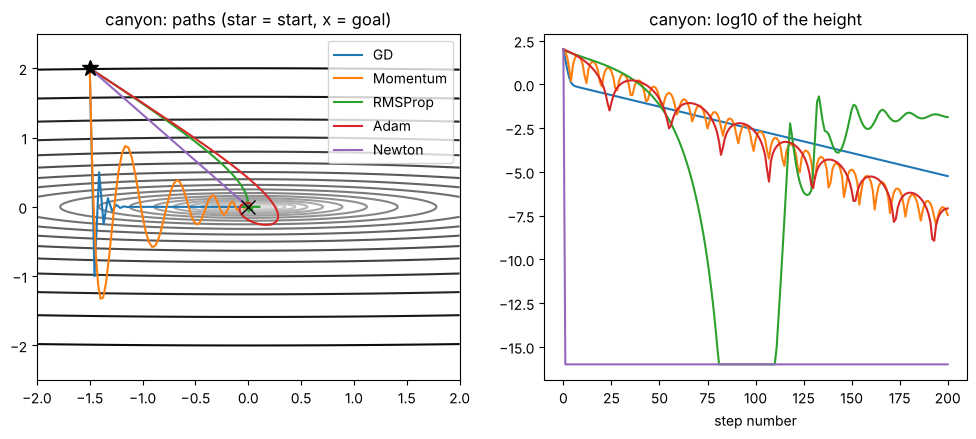

In [14]:
draw("canyon", np.linspace(-2, 2, 300), np.linspace(-2.5, 2.5, 300), (0, 0))

**What we see on the Canyon**
- GD is slow. The learning rate must stay small because of the steep side,
  so it crawls along the flat side.
- Momentum and Adam get very close to the bottom.
- RMSProp keeps wobbling a little at the end, because its step size never gets smaller.
- Newton gets there in ONE step. The hill is a perfect bowl, and Newton knows its shape.

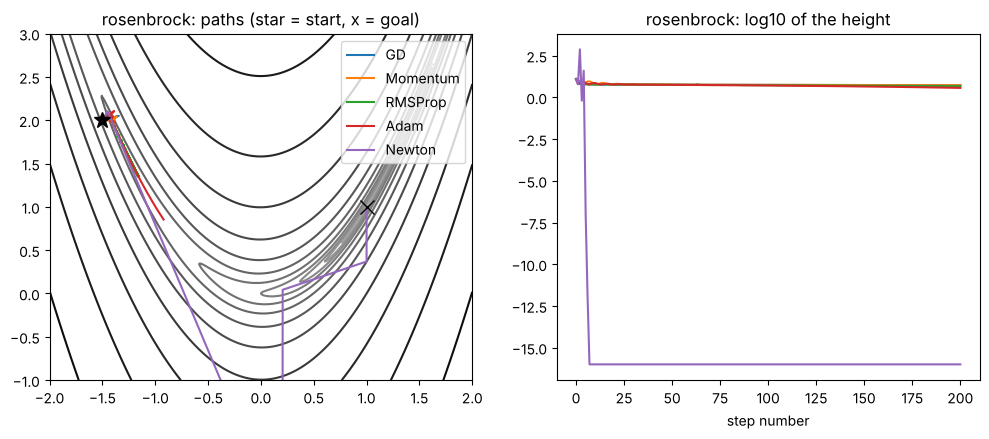

In [15]:
draw("rosenbrock", np.linspace(-2, 2, 300), np.linspace(-1, 3, 300), (1, 1))

**What we see on Rosenbrock**
- The banana valley is narrow and bends. GD, Momentum, RMSProp and Adam hardly move
  in 200 steps. They are still at the start of the valley.
- Newton reaches the bottom (1, 1), because it knows how the valley bends.

In [16]:
for name in results:
    print(name)
    for label, (path, heights) in results[name].items():
        print("   ", label, "final height:", "%.2e" % heights[-1])

canyon
    GD final height: 5.75e-06
    Momentum final height: 3.44e-08
    RMSProp final height: 1.36e-02
    Adam final height: 8.19e-08
    Newton final height: 0.00e+00
rosenbrock
    GD final height: 5.32e+00
    Momentum final height: 5.34e+00
    RMSProp final height: 4.69e+00
    Adam final height: 3.69e+00
    Newton final height: 0.00e+00


## Part 4: Experiment 2, a bigger race with 50,000 data points
Now we do something real: we teach a computer to guess numbers (linear regression).
We make fake data: 50,000 rows and 50 columns. We know the right answer (`w_true`),
so we can check how close each walker gets.

The 50 columns have very different sizes (from 0.1 to 10).
This makes the hill like a very narrow canyon, which is hard for plain GD.

The "loss" tells how wrong the guesses are. Small loss means good.

In [17]:
N = 50000      # number of data rows
d = 50         # number of columns (numbers to learn)
batch = 64     # small group of rows for the fast walkers

rng = np.random.default_rng(0)
sizes = np.logspace(-1, 1, d)
X = rng.standard_normal((N, d)) * sizes
w_true = rng.standard_normal(d)
y = X @ w_true + 0.1 * rng.standard_normal(N)

def loss(w):
    return 0.5 * np.mean((X @ w - y)**2)

print("Best possible loss (only noise left):", round(loss(w_true), 4))

Best possible loss (only noise left): 0.005


Two ways to get the slope:
- Full batch: look at all 50,000 rows. Exact, but slow.
- Mini batch: look at only 64 random rows. A bit shaky, but very fast.

In [18]:
def get_slope(w, use_batch):
    if not use_batch:
        return X.T @ (X @ w - y) / N
    i = rng.integers(0, N, batch)
    Xb = X[i]
    yb = y[i]
    return Xb.T @ (Xb @ w - yb) / batch

`train` lets a walker take many steps and writes down the time and the loss.
We only count the time for the walking itself, not for measuring the loss.

In [19]:
def train(walker, steps, use_batch, every=100):
    w = np.zeros(d)
    clock = 0.0
    times, losses = [], []
    for t in range(steps + 1):
        if t % every == 0:
            times.append(clock)
            losses.append(loss(w))
        begin = time.time()
        g = get_slope(w, use_batch)
        w = walker.step(w, g)
        clock += time.time() - begin
    return times, losses

The biggest curvature of the hill (`lam`) tells us a safe learning rate for plain GD.
A learning rate of 1/lam is safe.

In [20]:
lam = np.linalg.eigvalsh(X.T @ X / N).max()

race = {
    "Full-batch GD": train(GD(1 / lam), 300, False, 5),
    "Mini-batch SGD": train(GD(0.1 / lam), 6000, True),
    "Momentum": train(Momentum(0.1 / lam, 0.9), 6000, True),
    "RMSProp": train(RMSProp(0.01, 0.99), 6000, True),
    "Adam": train(Adam(0.02), 6000, True),
}

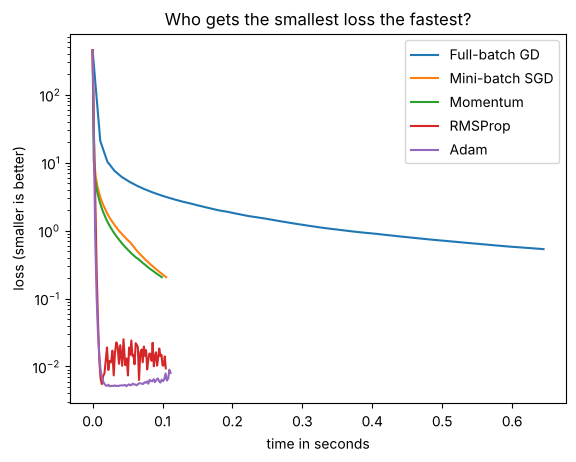

In [21]:
for name, (times, losses) in race.items():
    plt.plot(times, losses, label=name)
plt.yscale("log")
plt.xlabel("time in seconds")
plt.ylabel("loss (smaller is better)")
plt.title("Who gets the smallest loss the fastest?")
plt.legend()
plt.savefig("experiment2.png")
plt.show()

In [22]:
for name, (times, losses) in race.items():
    print("%-15s loss: %.4f   time: %.2f s" % (name, losses[-1], times[-1]))

Full-batch GD   loss: 0.5339   time: 0.64 s
Mini-batch SGD  loss: 0.2066   time: 0.11 s
Momentum        loss: 0.2063   time: 0.10 s
RMSProp         loss: 0.0094   time: 0.10 s
Adam            loss: 0.0080   time: 0.11 s


**What we see**
- Full-batch GD is the slowest and ends with the biggest loss.
  Every step reads all 50,000 rows, and it still wobbles in the narrow canyon.
- Mini-batch SGD and Momentum are faster per step, but still not close to the best.
- RMSProp and Adam get very close to the best possible loss.
  They give each of the 50 numbers its own step size, which is what this hill needs.

(If you run it again the times can change a little. That is normal.)

**Memory:** the extra memory is tiny. Momentum and RMSProp keep 1 list of 50 numbers.
Adam keeps 2 lists (100 numbers). The data itself has 50,000 x 50 = 2.5 million numbers,
so the walkers' memory is nothing compared to the data.

## Part 5: The complexity table (Question 6)
d = how many numbers we learn, N = how many data rows, b = size of the small batch.

| Walker | Time for one step | Extra memory | In simple words |
|---|---|---|---|
| Batch GD | N * d | 0 | exact slope, but slow, it reads all the data |
| Mini-batch SGD | b * d | 0 | fast steps, but shaky |
| Momentum | b * d | d | smoother, less zig-zag |
| RMSProp | b * d | d | own step size for every number |
| Adam | b * d | 2d | works well almost everywhere |
| Newton | N * d^2 + d^3 | d^2 | very few steps, but too expensive when d is big |

## The end: what did we learn?
- Plain gradient descent works, but it is slow and zig-zags.
- Each new walker fixes one problem of the one before it.
- Adam is a very good all-round choice.
- Newton is the fastest, but it needs a huge table (H), so we cannot use it for big problems.